# 01 – EDA: NASA C-MAPSS FD001

**Ziel:** Datenstruktur verstehen, nutzlose Sensoren identifizieren, Degradationsverläufe sichtbar machen, RUL-Label begründen.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
cols = ["unit", "cycle", "op1", "op2","op3","s1", "s2", "s3", "s4", "s5", "s6", "s7", "s8", "s9", "s10", "s11", "s12", "s13", "s14", "s15", "s16", "s17", "s18", "s19", "s20", "s21"]

train = pd.read_csv("../data/raw/train_FD001.txt", sep = r"\s+", header = None, names = cols)
test = pd.read_csv("../data/raw/test_FD001.txt", sep = r"\s+", header = None, names = cols)
rul = pd.read_csv("../data/raw/RUL_FD001.txt", sep = r"\s+", header = None, names = ["RUL"])

In [3]:
train.shape

(20631, 26)

In [4]:
test.shape

(13096, 26)

In [5]:
rul.shape

(100, 1)

In [6]:
train.isna().sum()

unit     0
cycle    0
op1      0
op2      0
op3      0
s1       0
s2       0
s3       0
s4       0
s5       0
s6       0
s7       0
s8       0
s9       0
s10      0
s11      0
s12      0
s13      0
s14      0
s15      0
s16      0
s17      0
s18      0
s19      0
s20      0
s21      0
dtype: int64

In [7]:
test.isna().sum()

unit     0
cycle    0
op1      0
op2      0
op3      0
s1       0
s2       0
s3       0
s4       0
s5       0
s6       0
s7       0
s8       0
s9       0
s10      0
s11      0
s12      0
s13      0
s14      0
s15      0
s16      0
s17      0
s18      0
s19      0
s20      0
s21      0
dtype: int64

In [8]:
train["unit"].nunique()

100

In [9]:
lifetimes = train.groupby("unit")["cycle"].max()
lifetimes.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

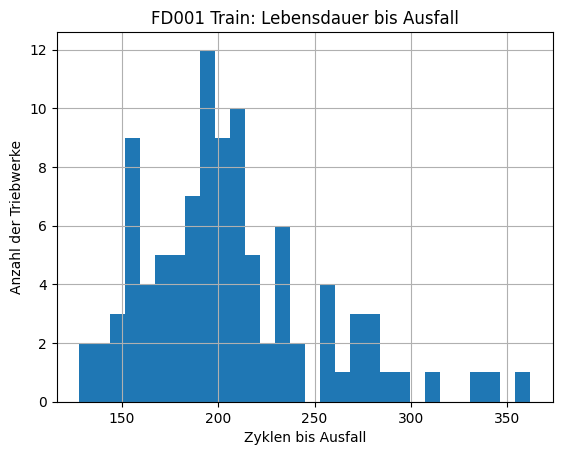

In [10]:
lifetimes.hist(bins =30)
plt.title("FD001 Train: Lebensdauer bis Ausfall")
plt.xlabel("Zyklen bis Ausfall")
plt.ylabel("Anzahl der Triebwerke")
plt.show

-Minimale Lebensdauer der Triebwerke bei 128 Zyklen,     Maximum bei 362 Zyklen, Durchschnitt bei ca 206 Zyklen

-Die Lebensdauern streuen stark (min 128 bis max 362). Kennt man nur den aktuellen Zyklus, liegt die Restlebensdauer deshalb in einem Bereich von über 200 Zyklen. Hypothese: Die Sensorverläufe zeigen den Verschleiß und erlauben eine genauere Schätzung. Das prüfe ich im nächsten Abschnitt.

Ist max(cycle) pro Triebwerk in Test genau so groß wie in train?

In [11]:
test["unit"].nunique()

100

In [12]:
test_lt = test.groupby("unit")["cycle"].max()

<function matplotlib.pyplot.show(close=None, block=None)>

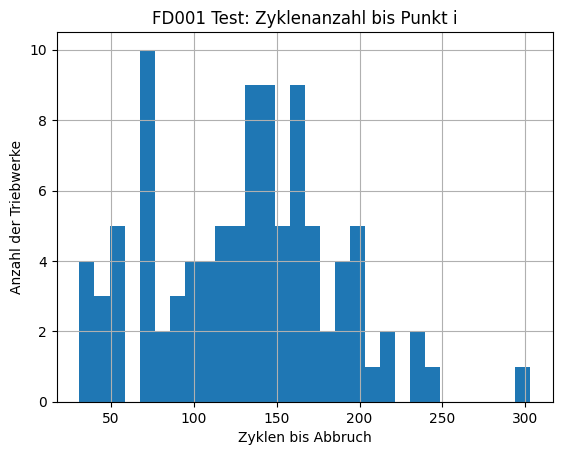

In [13]:
test_lt.hist(bins = 30)
plt.title("FD001 Test: Zyklenanzahl bis Punkt i")
plt.xlabel("Zyklen bis Abbruch")
plt.ylabel("Anzahl der Triebwerke")
plt.show

In [14]:
test_lt.describe()

count    100.000000
mean     130.960000
std       53.593479
min       31.000000
25%       88.750000
50%      133.500000
75%      164.250000
max      303.000000
Name: cycle, dtype: float64

Testset hat stark abweichende Werte, Minimum der Zyklen bei 31 und Maximum bei 303, Durchschnitt ebenfalls stark verlagert von 206 auf 131 Zyklen

In [15]:
rul.describe()

,RUL
count,100.00000
mean,75.52000
std,41.76497
min,7.00000
25%,32.75000
50%,86.00000
75%,112.25000
max,145.00000


In [16]:
train["max_cycle"] = train.groupby("unit")["cycle"].transform("max")

In [17]:
last_cycle = test.groupby("unit").last()
rul.index = rul.index + 1

In [18]:
test_lifetime = last_cycle["cycle"]+rul["RUL"]
print(test_lifetime)

unit
1      143
2      147
3      195
4      188
5      189
      ... 
96     234
97     216
98     180
99     214
100    218
Length: 100, dtype: int64


In [19]:
test_lifetime.describe()

count    100.000000
mean     206.480000
std       44.041872
min      141.000000
25%      174.750000
50%      199.000000
75%      227.750000
max      341.000000
dtype: float64

In [20]:
train.groupby("unit")["cycle"].max().describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

Es zeigt sich dass im Test-Set der selbe Prozess wie im Train-Set genutzt wurde und dieser lediglich zu einem früheren Zeitpunkt abgeschnitten wurde.

In [21]:
train.std()

unit         2.922763e+01
cycle        6.888099e+01
op1          2.187313e-03
op2          2.930621e-04
op3          0.000000e+00
s1           0.000000e+00
s2           5.000533e-01
s3           6.131150e+00
s4           9.000605e+00
s5           5.329200e-15
s6           1.388985e-03
s7           8.850923e-01
s8           7.098548e-02
s9           2.208288e+01
s10          0.000000e+00
s11          2.670874e-01
s12          7.375534e-01
s13          7.191892e-02
s14          1.907618e+01
s15          3.750504e-02
s16          3.469531e-18
s17          1.548763e+00
s18          0.000000e+00
s19          0.000000e+00
s20          1.807464e-01
s21          1.082509e-01
max_cycle    5.002860e+01
dtype: float64

In [22]:
train[["op1","op2","s5","s6","s16"]].nunique()

op1    158
op2     13
s5       1
s6       2
s16      1
dtype: int64

In [23]:
drop_cols = ["op3", "s1", "s5", "s10", "s16", "s18", "s19"]

In [24]:
train["s6"].value_counts()

s6
21.61    20225
21.60      406
Name: count, dtype: int64

In [25]:
train["RUL"] = train["max_cycle"] - train["cycle"]

In [26]:
train.groupby("unit")["RUL"].min().unique()

array([0])

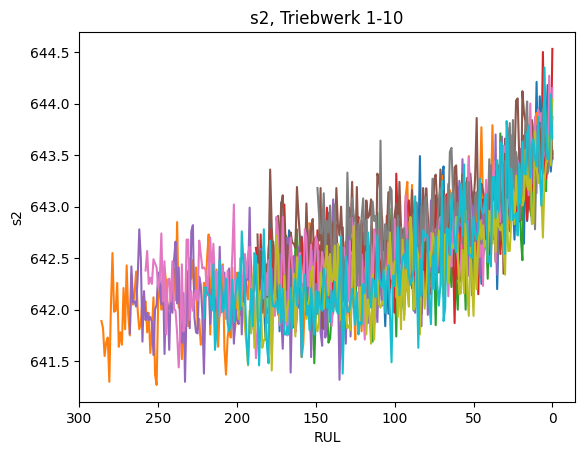

In [27]:
for i in range(1,11):
    unit_i = train[train["unit"]==i]
    plt.plot(unit_i["RUL"], unit_i["s2"])

plt.gca().invert_xaxis()
plt.title("s2, Triebwerk 1-10")
plt.xlabel("RUL")
plt.ylabel("s2")
plt.show()

In [28]:
meta_cols= ["unit", "cycle", "max_cycle", "RUL"]
plot_cols = [c for c in train.columns if c not in drop_cols+ meta_cols]

In [29]:
len(plot_cols)

17

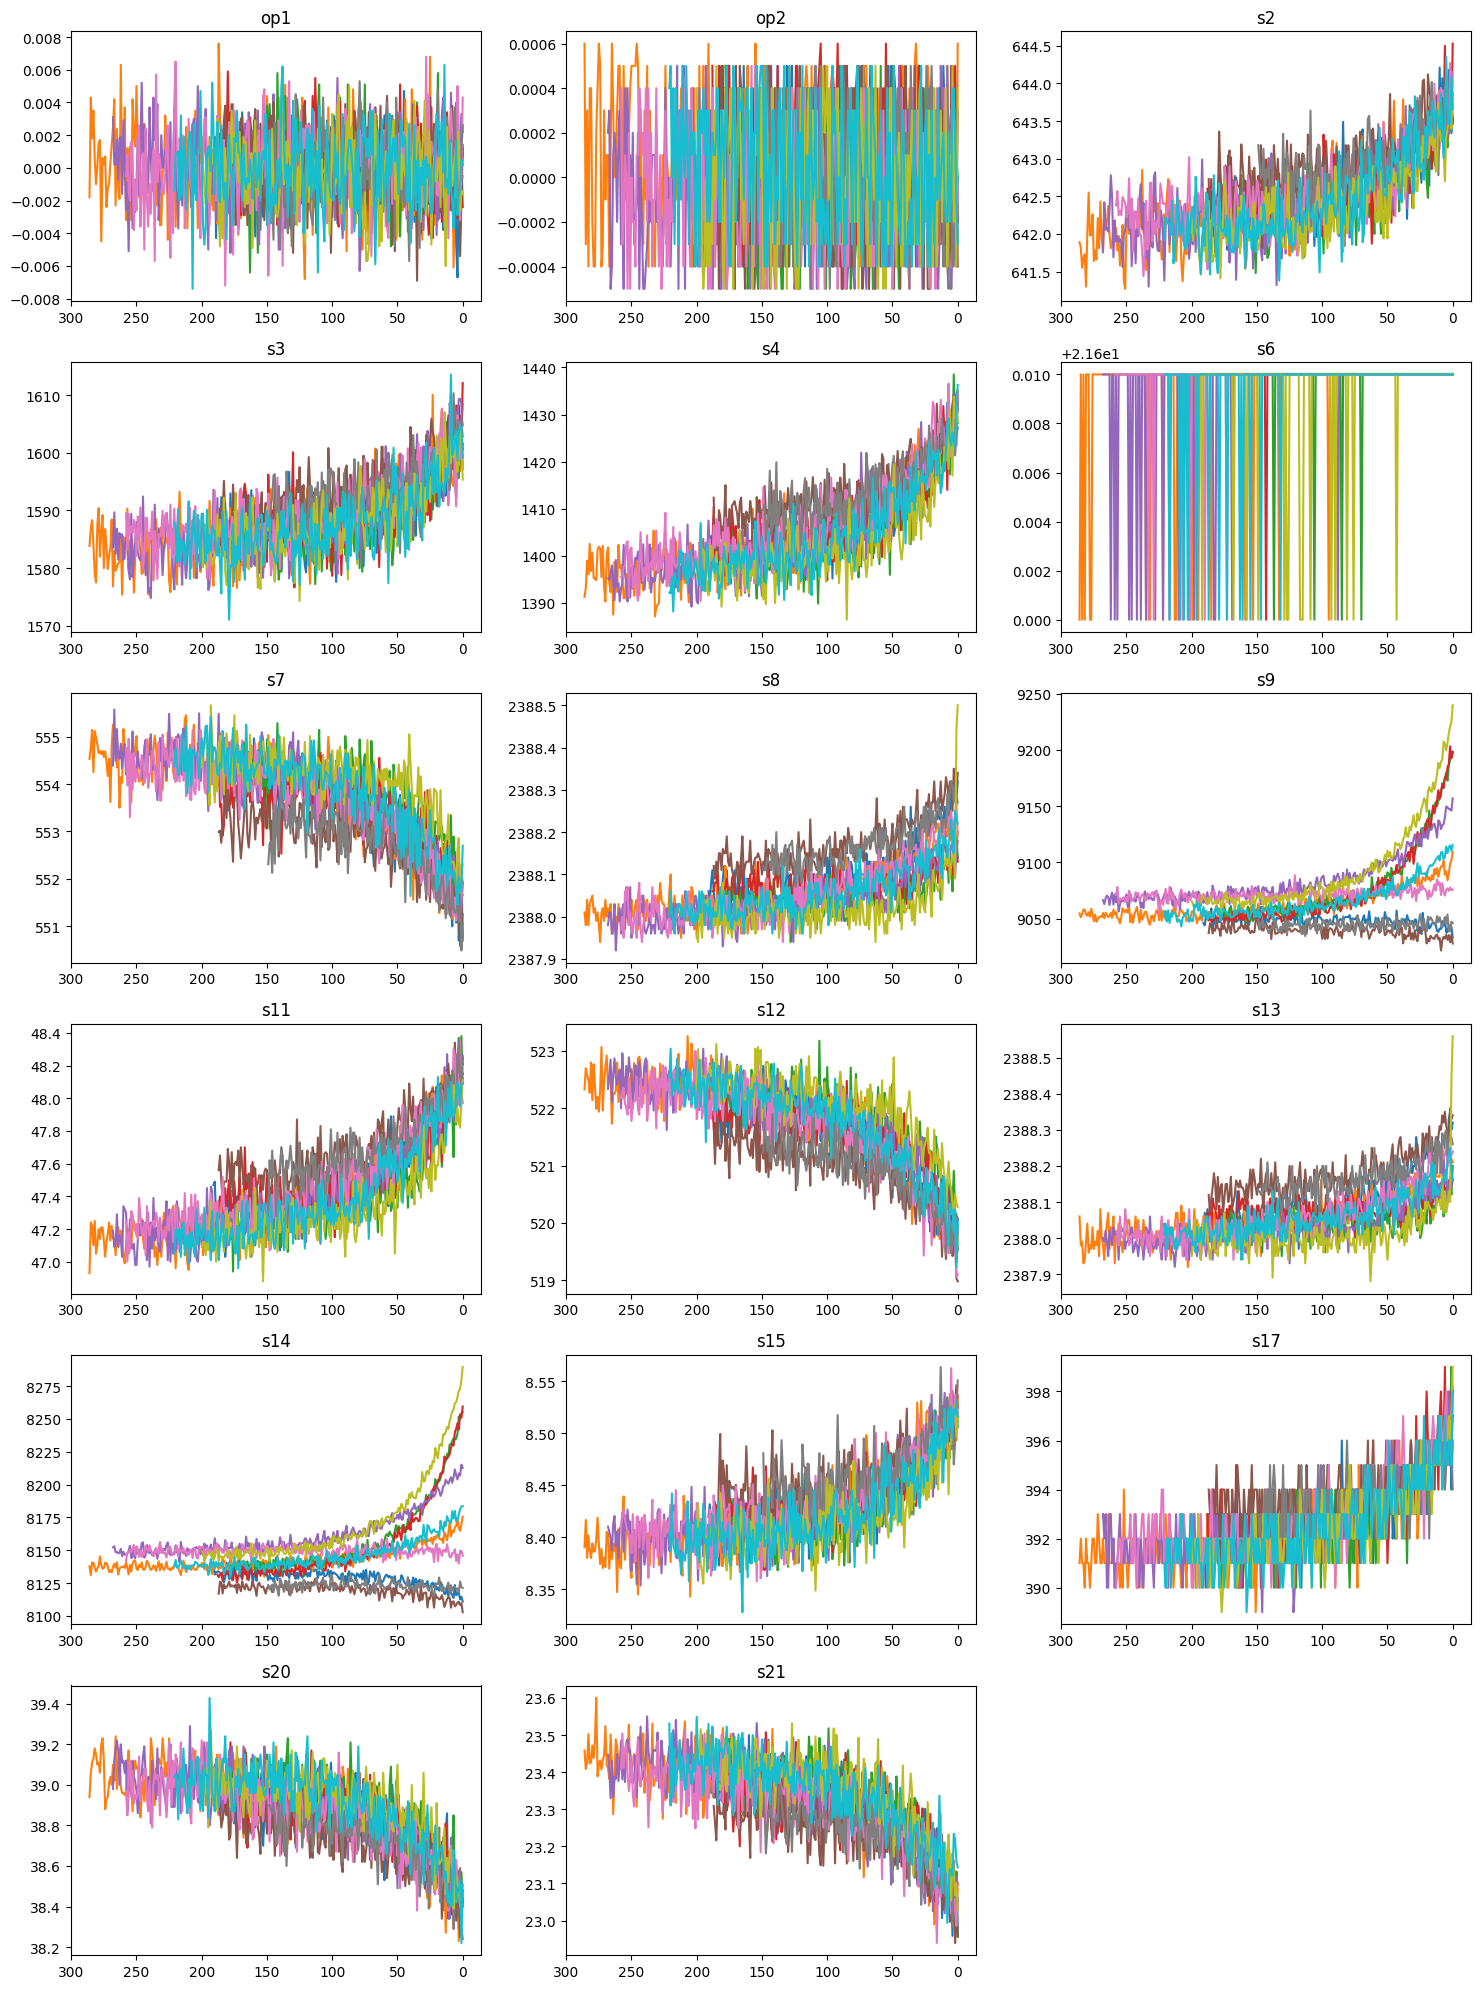

In [30]:
fig, axes = plt.subplots(6, 3, figsize=(15,20))
axes = axes.flatten()
for ax, col in zip(axes, plot_cols):
    for i in range(1,11):
        unit_i = train[train["unit"]==i]
        ax.plot(unit_i["RUL"], unit_i[col])
    ax.set_title(col)
    ax.invert_xaxis()

axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [31]:
up = ["s2", "s3", "s4", "s8", "s11", "s13", "s15", "s17"]
down= ["s7", "s12", "s20", "s21"]
flat= ["op1", "op2", "s6"]
ambiguous=["s9", "s14"]

In [32]:
drop_cols += ["op1", "op2"]
train[["s9", "s14"]].corr()

,s9,s14
s9,1.000000,0.963157
s14,0.963157,1.000000


Trends sichtbar ab ca 125 Zyklen RUL

Gedroppte Spalten (drop_cols) sind entweder Trendlos oder Varianzlos und haben somit keine aussagekraft im weiteren Verlauf
Mehrdeutige Spalten (s9,s14) sind fast exakt miteinander korreliert, sagen also ungefähr das selbe voraus. Folgerung: Entweder zusammenfassen oder einen der beiden Sensoren streichen.

In [33]:
train["s6"].value_counts(normalize=True)
train.groupby("s6")["RUL"].describe()

,count,mean,std,min,25%,50%,75%,max
s6,,,,,,,,
21.60,406.0,170.204433,54.825065,43.0,131.0,171.0,205.0,324.0
21.61,20225.0,106.555303,68.555948,0.0,50.0,101.0,154.0,361.0


In [34]:
selten = train[train["s6"]==21.60]
(selten["RUL"] > 125).mean()

np.float64(0.7906403940886699)

In [35]:
selten["unit"].nunique()

62

In [36]:
drop_cols += ["s6"]

In [37]:
print(drop_cols)

['op3', 's1', 's5', 's10', 's16', 's18', 's19', 'op1', 'op2', 's6']


## Zusammenfassung der EDA

**1. Train vs. Test**
Train enthält 100 Triebwerke mit vollständigem Verlauf bis zum Ausfall (20.631 Zeilen, Lebensdauer 128–362 Zyklen, Mittel ≈ 206). Test enthält 100 andere Triebwerke desselben Typs. Ihre Zeitreihen enden an einem zufälligen Punkt vor dem Ausfall (13.096 Zeilen, 31–303 beobachtete Zyklen, Mittel ≈ 131). Die wahre RUL am letzten beobachteten Zyklus steht in `RUL_FD001.txt` (7–145 Zyklen, Mittel ≈ 76). Bewertet wird nur die Vorhersage am letzten Zyklus jedes Testtriebwerks, also 100 Vorhersagen.

**2. Plausibilitätscheck**
Beobachtete Testzyklen plus wahre RUL ergeben die Gesamtlebensdauer der Testtriebwerke. Ihr Mittel liegt bei ≈ 206 Zyklen und damit praktisch gleichauf mit Train (≈ 206). Train und Test stammen also aus derselben Population. Ein Modell, das auf Train lernt, sollte sich daher auf Test übertragen lassen.

**3. Gedroppte Spalten**
- `op3`, `s1`, `s5`, `s10`, `s16`, `s18`, `s19`: Standardabweichung 0 bzw. nahe 0. Die Spalten sind konstant und tragen keine Information.
- `op1`, `op2`: FD001 hat nur einen Betriebszustand. Die beiden Einstellungen schwanken lediglich als Rauschen um diesen Zustand und haben keinen Bezug zur Degradation.
- `s6` (quasi-konstant): 98 % der Zeilen haben den Wert 21,61, 2 % den Wert 21,60. Der Unterschied liegt nur in der letzten Nachkommastelle, also in der Auflösung des Sensors. Der seltene Wert tritt früher im Leben auf (mittlere RUL ≈ 170 statt ≈ 107, Minimum 43, verteilt auf 62 Triebwerke). 79 % dieser Zeilen liegen jedoch über RUL 125 und erhalten nach der Kappung ohnehin das konstante Label 125. Vermutlich steigt der Druck mit dem Alter minimal an und überschreitet irgendwann die Rundungsgrenze. Andere Sensoren zeigen den Degradationstrend deutlich stärker, `s6` liefert also kaum zusätzliche Information.

Es bleiben 14 Sensoren: `s2`, `s3`, `s4`, `s7`, `s8`, `s9`, `s11`, `s12`, `s13`, `s14`, `s15`, `s17`, `s20`, `s21`.

**4. Sensorgruppen** (visuell anhand der Verläufe über die RUL eingeteilt)
- up: `s2`, `s3`, `s4`, `s8`, `s11`, `s13`, `s15`, `s17`
- down: `s7`, `s12`, `s20`, `s21`
- ambiguous: `s9`, `s14`. Der Verlauf unterscheidet sich je nach Triebwerk, bei einigen steigt er, bei anderen fällt er. Offene Frage für das Feature Engineering: Löst eine Normalisierung je Triebwerk auf den Startzustand das Problem?

**5. Kappung der RUL bei 125**
Im frühen Lebensabschnitt verlaufen die Sensoren flach. Ein Trend wird erst ab etwa RUL 125 erkennbar. Ohne Kappung müsste das Modell z. B. RUL 300 von RUL 200 unterscheiden, obwohl die Sensoren dort kein Signal liefern. Das erzeugt große Fehler im jungen Bereich. Deshalb wird das Label stückweise linear definiert: `RUL_gekappt = min(RUL, 125)`. Solange das Triebwerk gesund ist, bleibt das Label konstant bei 125, danach fällt es linear bis 0. Der Wert liegt in dem in der Literatur üblichen Bereich von 120–130. Für die Bewertung kostet die Kappung wenig: Nur 11 von 100 Testtriebwerken haben eine wahre RUL über 125.